# 02. Probability and Uncertainty: Bayesian Network

Pada Notebook 01, Anda telah menghitung peluang dari tabel joint dan menggunakan aturan Bayes. Dalam notebook ini, Anda akan mempelajari **Bayesian Network**, yaitu model yang menyatakan hubungan antarvariabel melalui graf dan tabel probabilitas.

Sebagai contoh, John dan Mary menelepon karena mendengar alarm rumah. Alarm dapat dipicu oleh pencurian maupun gempa. Untuk menghitung peluang terjadinya pencurian setelah menerima kedua telepon tersebut, kita perlu memperhitungkan beberapa kemungkinan penyebab alarm.

Setelah menyelesaikan notebook ini, mahasiswa diharapkan mampu:

1. membaca graf Bayesian Network dan conditional probability table (CPT);
2. menghitung peluang joint dari CPT dan menjelaskan independensi bersyarat;
3. menghitung posterior dengan enumeration dan variable elimination;
4. menjelaskan cara kerja prior sampling, rejection sampling, likelihood weighting, dan Gibbs sampling;
5. membangun Bayesian Network sederhana dan menafsirkan hasil inferensinya.

**Prasyarat:** joint, marginal, conditional probability, dan aturan Bayes pada `01 - Probability Distribution.ipynb`.

## Setup

Jalankan sel berikut sebelum mengerjakan materi. Sel ini memasang NumPy, pandas, dan Matplotlib jika paket tersebut belum tersedia. Notebook dapat dijalankan di Jupyter atau Google Colab.

Semua contoh menggunakan variabel Boolean, dengan nilai `True` atau `False`. Jaringan dan CPT disimpan dalam dictionary Python. Fungsi untuk membaca CPT dan menghitung peluang akan diperkenalkan pada bagian yang menggunakannya.

Jalankan sel secara berurutan. Bagian 2.1-2.5 membahas representasi jaringan dan inferensi exact, sedangkan bagian 2.6-2.8 membahas inferensi melalui sampling. Latihan soal tersedia di akhir notebook.

In [1]:
# Standard setup cell - run before other cells.
import importlib.util
import itertools
import math
import subprocess
import sys


def ensure_dependencies():
    """Install only packages used by this notebook."""
    required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
    missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


ensure_dependencies()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VALUES = (True, False)
print("Python:", sys.version.split()[0])
print("Setup selesai. Variabel jaringan memakai True dan False.")

Python: 3.10.20
Setup selesai. Variabel jaringan memakai True dan False.


---
## 2.1 Membaca jaringan dan CPT

### Penjelasan

Bayesian Network terdiri atas:

- **Graf berarah tanpa siklus (directed acyclic graph atau DAG).** Setiap node mewakili satu variabel acak. Node yang memiliki panah langsung menuju node lain disebut **parent**, sedangkan node yang dituju disebut **child**. Jika arah panah diikuti, tidak boleh ada lintasan yang kembali ke node asal.
- **Conditional probability table (CPT).** Tabel ini menyimpan peluang suatu variabel untuk setiap kombinasi nilai parent-nya. Node tanpa parent menyimpan peluang awal atau **prior**.

Perhatikan contoh alarm rumah berikut. Alarm dapat berbunyi karena pencurian atau gempa. John dan Mary mungkin menelepon ketika mendengar alarm, tetapi mereka juga dapat menelepon ketika alarm tidak berbunyi.

| Simbol | Nama pada kode | Arti nilai True |
|---|---|---|
| $B$ | Burglary | terjadi pencurian |
| $E$ | Earthquake | terjadi gempa |
| $A$ | Alarm | alarm berbunyi |
| $J$ | JohnCalls | John menelepon |
| $M$ | MaryCalls | Mary menelepon |

Struktur jaringannya adalah $B\to A\leftarrow E$, dengan $A\to J$ dan $A\to M$. Jadi, Alarm memiliki dua parent, yaitu Burglary dan Earthquake, serta dua child, yaitu JohnCalls dan MaryCalls.

Gunakan prior $P(B=True)=0{,}001$ dan $P(E=True)=0{,}002$, serta CPT berikut.

| Burglary | Earthquake | $P(Alarm=True\mid Burglary,Earthquake)$ |
|---|---|---|
| True | True | 0,95 |
| True | False | 0,94 |
| False | True | 0,29 |
| False | False | 0,001 |

| Alarm | $P(JohnCalls=True\mid Alarm)$ | $P(MaryCalls=True\mid Alarm)$ |
|---|---|---|
| True | 0,90 | 0,70 |
| False | 0,05 | 0,01 |

Karena variabelnya Boolean, peluang False dapat dihitung dari komplemennya:

$$P(X=False\mid parents)=1-P(X=True\mid parents).$$

Misalnya, jika ada pencurian tanpa gempa, peluang alarm berbunyi adalah 0,94. Peluang alarm tidak berbunyi pada kondisi yang sama adalah $1-0{,}94=0{,}06$.

Pada contoh ini, arah panah mengikuti dugaan hubungan sebab-akibat. Secara umum, graf Bayesian Network menyatakan asumsi hubungan probabilistik; arah panah saja belum cukup untuk membuktikan sebab-akibat. Perhitungan peluang juga dapat menggunakan informasi dari child untuk mencari peluang parent, seperti menghitung peluang pencurian berdasarkan telepon John.

### Contoh penerapan

Setiap node disimpan dalam dictionary dengan entri `parents` dan `cpt`. Kunci pada `cpt` berupa tuple nilai parent sesuai urutan dalam `parents`. Node tanpa parent menggunakan tuple kosong `()`.

Node disusun dalam **urutan topologis**: setiap parent ditulis sebelum child-nya. Dengan urutan ini, nilai parent sudah tersedia ketika child dihitung atau diambil sebagai sampel.

In [2]:
burglary = {
    "Burglary": {"parents": (), "cpt": {(): 0.001}},
    "Earthquake": {"parents": (), "cpt": {(): 0.002}},
    "Alarm": {
        "parents": ("Burglary", "Earthquake"),
        "cpt": {(True, True): 0.95, (True, False): 0.94,
                (False, True): 0.29, (False, False): 0.001},
    },
    "JohnCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.90, (False,): 0.05}},
    "MaryCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.70, (False,): 0.01}},
}


def validate_network(network):
    """Check parent order, complete Boolean CPTs, and probability ranges."""
    seen = set()
    for variable, node in network.items():
        parents = node["parents"]
        if len(parents) != len(set(parents)) or not set(parents) <= seen:
            raise ValueError(f"Invalid parent order for {variable}")
        expected = set(itertools.product(VALUES, repeat=len(parents)))
        if set(node["cpt"]) != expected:
            raise ValueError(f"Incomplete CPT for {variable}")
        if not all(0 <= probability <= 1 for probability in node["cpt"].values()):
            raise ValueError(f"Invalid probability for {variable}")
        seen.add(variable)


def node_probability(variable, value, event, network):
    """Return P(variable=value | its parents in event)."""
    node = network[variable]
    parent_values = tuple(event[parent] for parent in node["parents"])
    p_true = node["cpt"][parent_values]
    return p_true if value else 1 - p_true


validate_network(burglary)
print("P(Alarm=True | B=True, E=False) =",
      node_probability("Alarm", True, {"Burglary": True, "Earthquake": False}, burglary))
print("P(Alarm=False | B=True, E=False) =",
      round(node_probability("Alarm", False, {"Burglary": True, "Earthquake": False}, burglary), 2))

P(Alarm=True | B=True, E=False) = 0.94
P(Alarm=False | B=True, E=False) = 0.06


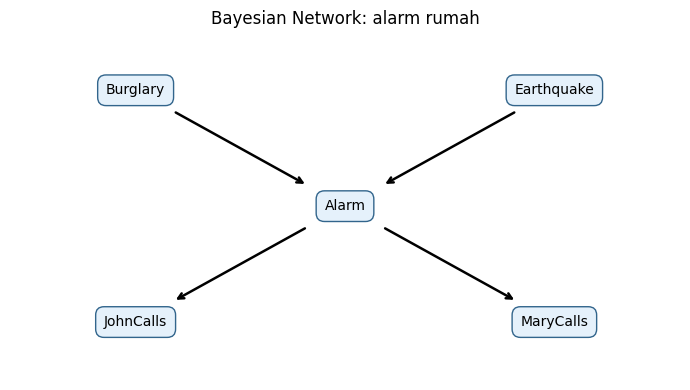

In [3]:
positions = {"Burglary": (0, 2), "Earthquake": (2, 2), "Alarm": (1, 1),
             "JohnCalls": (0, 0), "MaryCalls": (2, 0)}
fig, ax = plt.subplots(figsize=(7, 4))
for child, node in burglary.items():
    for parent in node["parents"]:
        ax.annotate("", xy=positions[child], xytext=positions[parent],
                    arrowprops={"arrowstyle": "->", "lw": 1.8,
                                "shrinkA": 33, "shrinkB": 33})
for variable, (x, y) in positions.items():
    ax.text(x, y, variable, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.6", "fc": "#e5f1fb", "ec": "#32658c"})
ax.set(xlim=(-0.6, 2.6), ylim=(-0.5, 2.5), title="Bayesian Network: alarm rumah")
ax.axis("off")
plt.tight_layout()
plt.show()

CPT Alarm memiliki empat kombinasi nilai parent karena ada dua parent Boolean. Kunci `(True, False)` menyatakan Burglary=True dan Earthquake=False, sesuai urutan pada `parents`. Pada kondisi ini, peluang Alarm=True adalah 0,94 dan peluang Alarm=False adalah 0,06.

---
## 2.2 Dari CPT ke joint distribution

### Penjelasan

Pada Notebook 01, tabel joint memuat peluang setiap kombinasi nilai variabel. Bayesian Network menyimpan distribusi tersebut dalam bentuk CPT. Peluang satu kombinasi lengkap dihitung dengan mengalikan peluang setiap node berdasarkan nilai parent-nya:

$$P(x_1,\ldots,x_n)=\prod_{i=1}^{n}P(x_i\mid parents(X_i)).$$

Untuk jaringan alarm, faktorisasi joint-nya adalah:

$$P(B,E,A,J,M)=P(B)P(E)P(A\mid B,E)P(J\mid A)P(M\mid A).$$

Faktorisasi ini diperoleh dari chain rule dengan menggunakan asumsi independensi bersyarat pada graf. Contohnya, setelah nilai Alarm diketahui, peluang JohnCalls dalam model ini cukup dihitung dari CPT JohnCalls.

Misalkan terjadi pencurian, tidak ada gempa, alarm berbunyi, dan kedua tetangga menelepon. Peluang kelima kejadian tersebut terjadi bersamaan adalah:

$$P(b,\neg e,a,j,m)=0{,}001\times0{,}998\times0{,}94\times0{,}90\times0{,}70=0{,}0005910156.$$

Huruf kecil seperti $b$ menyatakan Burglary=True, sedangkan $\neg b$ menyatakan Burglary=False. Perhatikan bahwa $P(b,\neg e,a,j,m)$ adalah peluang joint. Untuk memperoleh peluang pencurian setelah kedua tetangga menelepon, kita masih perlu menjumlahkan variabel yang tidak diamati dan melakukan normalisasi.

Tabel joint lima variabel Boolean memiliki $2^5=32$ baris. Karena total peluangnya harus 1, sebanyak 31 nilai dapat ditentukan secara bebas; nilai terakhir mengikuti dari jumlah tersebut. Jaringan alarm hanya memerlukan $1+1+4+2+2=10$ peluang True pada CPT. Jumlah yang lebih sedikit ini dimungkinkan oleh asumsi independensi dalam model. Jaringan dengan banyak parent pada setiap node tetap dapat memiliki CPT yang besar.

### Contoh penerapan

In [4]:
def all_events(variables):
    """Generate every Boolean assignment of the given variables."""
    variables = list(variables)
    for values in itertools.product(VALUES, repeat=len(variables)):
        yield dict(zip(variables, values))


def joint_probability(event, network):
    """Return the joint probability of a complete assignment."""
    return math.prod(node_probability(variable, event[variable], event, network)
                     for variable in network)


event = {"Burglary": True, "Earthquake": False, "Alarm": True,
         "JohnCalls": True, "MaryCalls": True}
print(f"P(b, not e, a, j, m) = {joint_probability(event, burglary):.10f}")

full_joint = pd.DataFrame([
    {**event, "probability": joint_probability(event, burglary)}
    for event in all_events(burglary)
])
print("Jumlah baris:", len(full_joint))
print("Total peluang:", full_joint["probability"].sum())
assert np.isclose(full_joint["probability"].sum(), 1)
display(full_joint.head(8))

P(b, not e, a, j, m) = 0.0005910156
Jumlah baris: 32
Total peluang: 0.9999999999999999


,Burglary,Earthquake,Alarm,JohnCalls,MaryCalls,probability
0,True,True,True,True,True,1.197000e-06
1,True,True,True,True,False,5.130000e-07
2,True,True,True,False,True,1.330000e-07
3,True,True,True,False,False,5.700000e-08
4,True,True,False,True,True,5.000000e-11
5,True,True,False,True,False,4.950000e-09
6,True,True,False,False,True,9.500000e-10
7,True,True,False,False,False,9.405000e-08


Tabel yang dihasilkan memiliki 32 baris dengan total peluang 1. Setiap baris dihitung dari perkalian CPT. Tabel ini memperlihatkan bahwa jaringan alarm menyimpan distribusi joint yang lengkap meskipun hanya memuat sepuluh nilai probabilitas pada CPT.

---
## 2.3 Exact inference dengan enumeration

### Penjelasan

**Inferensi probabilistik** adalah proses menghitung peluang yang ditanyakan berdasarkan model dan informasi yang tersedia. Dalam sebuah query, variabel dibagi menjadi tiga kelompok:

| Peran | Arti | Pada $P(B\mid j,m)$ |
|---|---|---|
| Query | variabel yang dicari distribusinya | Burglary |
| Evidence | variabel yang nilainya sudah diamati | JohnCalls=True, MaryCalls=True |
| Hidden | variabel yang tidak menjadi query maupun evidence | Earthquake, Alarm |

**Enumeration** menghitung peluang untuk setiap kombinasi nilai hidden, menjumlahkannya, lalu menormalisasi hasil. Untuk $P(B\mid j,m)$, hitung dua nilai berikut:

$$s_b=P(b)\sum_e\sum_a P(e)P(a\mid b,e)P(j\mid a)P(m\mid a),$$
$$s_{\neg b}=P(\neg b)\sum_e\sum_a P(e)P(a\mid\neg b,e)P(j\mid a)P(m\mid a).$$

Setiap penjumlahan mencakup nilai True dan False. Nilai $s_b$ adalah $P(b,j,m)$, sedangkan $s_{\neg b}$ adalah $P(\neg b,j,m)$. Jumlah keduanya adalah $P(j,m)$, sehingga:

$$P(b\mid j,m)=\frac{s_b}{s_b+s_{\neg b}}.$$

Pembagian ini disebut **normalisasi**. Setelah dinormalisasi, peluang Burglary=True dan Burglary=False berjumlah 1. Evidence harus memiliki peluang positif agar probabilitas bersyaratnya terdefinisi.

Variabel yang tidak dicantumkan dalam evidence dianggap belum diketahui. Misalnya, evidence JohnCalls=True masih mencakup dua kemungkinan nilai MaryCalls.

### Contoh penerapan

Fungsi `enumeration_ask` menerima nama query, dictionary evidence, dan jaringan. Fungsi ini mengembalikan distribusi query untuk nilai True dan False. Variabel query tidak boleh sekaligus dicantumkan sebagai evidence.

In [5]:
def normalize(scores):
    """Convert nonnegative scores to a probability distribution."""
    total = sum(scores.values())
    if total <= 0:
        raise ValueError("Cannot normalize zero total probability or weight")
    return {value: score / total for value, score in scores.items()}


def check_query(query, evidence, network):
    """Check the Boolean query and evidence used in this notebook."""
    if query not in network or not set(evidence) <= set(network):
        raise ValueError("Unknown query or evidence variable")
    if query in evidence:
        raise ValueError("Query must be distinct from evidence")
    if any(type(value) is not bool for value in evidence.values()):
        raise ValueError("Evidence values must be True or False")


def enumeration_ask(query, evidence, network):
    """Compute P(query | evidence) by enumerating hidden variables."""
    check_query(query, evidence, network)
    hidden = [variable for variable in network if variable != query and variable not in evidence]
    scores = {}
    for value in VALUES:
        scores[value] = sum(
            joint_probability({**evidence, query: value, **hidden_event}, network)
            for hidden_event in all_events(hidden)
        )
    return normalize(scores)


call_evidence = {"JohnCalls": True, "MaryCalls": True}
posterior = enumeration_ask("Burglary", call_evidence, burglary)
print("Posterior Burglary:", posterior)
print(f"P(B=True | j,m) = {posterior[True]:.6f}")

selected = full_joint[full_joint["JohnCalls"] & full_joint["MaryCalls"]]
scores = selected.groupby("Burglary")["probability"].sum()
display(pd.DataFrame({"P(B,j,m)": scores, "P(B|j,m)": scores / scores.sum()}))
assert np.isclose(posterior[True], scores[True] / scores.sum())

Posterior Burglary: {True: 0.2841718353643929, False: 0.7158281646356071}
P(B=True | j,m) = 0.284172


,"P(B,j,m)","P(B|j,m)"
Burglary,,
False,0.001492,0.715828
True,0.000592,0.284172


Setelah John dan Mary menelepon, peluang pencurian naik dari 0,001 (0,1%) menjadi sekitar **0,284172 (28,42%)**. Peluang tidak terjadi pencurian adalah 0,715828. Model masih memperhitungkan kemungkinan gempa, alarm berbunyi tanpa pencurian atau gempa, serta telepon saat alarm tidak berbunyi.

Enumeration termasuk **exact inference**: hasil diperoleh dengan menjumlahkan seluruh kemungkinan yang diperlukan, bukan melalui perkiraan dari sampel. Nilainya tetap mengikuti CPT dan asumsi yang digunakan dalam model.

In [6]:
evidence_cases = {
    "Belum ada bukti": {},
    "John menelepon": {"JohnCalls": True},
    "John dan Mary menelepon": call_evidence,
    "John menelepon, Mary tidak": {"JohnCalls": True, "MaryCalls": False},
}
display(pd.DataFrame([
    {"Bukti": label, "P(Burglary=True | bukti)": enumeration_ask("Burglary", evidence, burglary)[True]}
    for label, evidence in evidence_cases.items()
]).round(6))

,Bukti,P(Burglary=True | bukti)
0,Belum ada bukti,0.001000
1,John menelepon,0.016284
2,John dan Mary menelepon,0.284172
3,"John menelepon, Mary tidak",0.005130


Pada baris "John menelepon", MaryCalls masih menjadi variabel hidden, sehingga peluang untuk kedua nilainya dijumlahkan. Pada baris "John menelepon, Mary tidak", MaryCalls=False sudah menjadi evidence. Perbedaan informasi ini menghasilkan posterior yang berbeda. Bukti tambahan dapat menaikkan atau menurunkan peluang pencurian.

---
## 2.4 Independensi bersyarat dan explaining away

### Penjelasan

Dua variabel disebut **independen** jika mengetahui nilai salah satunya tidak mengubah distribusi variabel lainnya. Jika sifat tersebut berlaku setelah nilai variabel $Z$ diketahui, keduanya disebut **independen bersyarat** pada $Z$:

$$X\perp Y\mid Z\quad\Longleftrightarrow\quad P(X\mid Y,Z)=P(X\mid Z),$$

untuk kondisi dengan peluang positif. Simbol $\perp$ dibaca "independen".

Tiga pola berikut sering muncul dalam Bayesian Network. Tabel ini berlaku untuk jaringan tiga node yang ditunjukkan, tanpa jalur lain atau evidence tambahan.

| Pola | Struktur | Hubungan kedua ujung |
|---|---|---|
| Chain | $X\to Z\to Y$ | independen setelah $Z$ diketahui |
| Fork / penyebab bersama | $X\leftarrow Z\to Y$ | independen setelah $Z$ diketahui |
| Collider / akibat bersama | $X\to Z\leftarrow Y$ | independen tanpa evidence; dapat menjadi bergantung jika $Z$ atau keturunannya diketahui |

Pada pola **fork** $J\leftarrow A\to M$, telepon John memberi informasi tentang Alarm dan, melalui Alarm, tentang kemungkinan Mary menelepon. Namun, jika nilai Alarm sudah diketahui, telepon John tidak lagi mengubah peluang Mary menelepon. Model ini mengasumsikan $J\perp M\mid A$.

Pada pola **collider** $B\to A\leftarrow E$, Burglary dan Earthquake independen sebelum ada evidence. Setelah diketahui alarm berbunyi, informasi tentang salah satu penyebab dapat mengubah peluang penyebab lainnya. Jika ternyata terjadi gempa, peluang pencurian dapat turun karena gempa dapat menjelaskan bunyi alarm. Pengaruh ini disebut **explaining away**.

Untuk jaringan yang lebih besar, semua jalur antarvariabel perlu diperiksa. Aturan pemeriksaan jalur tersebut disebut **d-separation**.

### Contoh penerapan

In [7]:
rows = []
for evidence in [
    {"Alarm": True},
    {"Alarm": True, "MaryCalls": True},
    {"Alarm": True, "MaryCalls": False},
]:
    rows.append({"Evidence": str(evidence),
                 "P(JohnCalls=True | evidence)": enumeration_ask("JohnCalls", evidence, burglary)[True]})
display(pd.DataFrame(rows))

comparison = {
    "Tanpa bukti": {},
    "Gempa terjadi": {"Earthquake": True},
    "Alarm berbunyi": {"Alarm": True},
    "Alarm berbunyi dan gempa terjadi": {"Alarm": True, "Earthquake": True},
}
display(pd.DataFrame([
    {"Evidence": label, "P(Burglary=True | evidence)": enumeration_ask("Burglary", evidence, burglary)[True]}
    for label, evidence in comparison.items()
]).round(6))

,Evidence,P(JohnCalls=True | evidence)
0,{'Alarm': True},0.9
1,"{'Alarm': True, 'MaryCalls': True}",0.9
2,"{'Alarm': True, 'MaryCalls': False}",0.9


,Evidence,P(Burglary=True | evidence)
0,Tanpa bukti,0.001000
1,Gempa terjadi,0.001000
2,Alarm berbunyi,0.373551
3,Alarm berbunyi dan gempa terjadi,0.003268


Pada tabel pertama, peluang John menelepon selalu 0,90 ketika Alarm=True, baik Mary menelepon maupun tidak. Hasil ini sesuai dengan asumsi $J\perp M\mid A$.

Pada tabel kedua, informasi gempa saja tidak mengubah peluang pencurian, yaitu 0,001. Setelah Alarm=True diketahui, peluang pencurian menjadi 0,373551. Jika ditambahkan evidence Earthquake=True, peluang itu turun menjadi 0,003268. Hasil ini menunjukkan explaining away: informasi tentang gempa mengurangi dugaan bahwa pencurian memicu alarm.

---
## 2.5 Variable elimination

### Penjelasan

Pada enumeration, beberapa perkalian dapat dihitung berulang kali. **Variable elimination** mengurangi pengulangan ini dengan menyimpan hasil perhitungan sementara dan menjumlahkan variabel secara bertahap.

Hasil sementara disimpan dalam **factor**, yaitu tabel nilai yang bergantung pada beberapa variabel. Total nilai sebuah factor tidak harus 1. Ada dua operasi utama:

1. **Pointwise product:** mengalikan nilai factor pada kombinasi variabel yang sesuai.
2. **Sum out:** menjumlahkan semua nilai suatu variabel agar variabel itu tidak lagi muncul dalam factor.

Untuk menghitung $P(B\mid j,m)$, eliminasi $E$ terlebih dahulu:

$$f(B,A)=\sum_e P(e)P(A\mid B,e).$$

Factor $f$ menyimpan hasil untuk setiap kombinasi Burglary dan Alarm. Selanjutnya, kalikan dengan peluang kedua telepon dan jumlahkan Alarm:

$$g(B)=\sum_a f(B,a)P(j\mid a)P(m\mid a).$$

Terakhir, kalikan dengan prior Burglary dan lakukan normalisasi:

$$P(B\mid j,m)=\operatorname{normalize}\big(P(B)g(B)\big).$$

Variabel hidden dijumlahkan, nilai evidence ditetapkan sesuai pengamatan, dan variabel query dipertahankan sampai akhir.

Urutan eliminasi menentukan ukuran factor sementara. Factor yang besar membutuhkan lebih banyak waktu dan memori. Karena itu, variable elimination tetap dapat memerlukan banyak perhitungan pada jaringan yang memiliki banyak hubungan antarvariabel. Pada jaringan kecil, waktu untuk membentuk dan mengelola factor juga dapat mengimbangi penghematan perhitungannya.

### Contoh penerapan

Kode berikut menghitung $P(B\mid j,m)$ pada jaringan alarm dengan mengeliminasi Earthquake, kemudian Alarm. Setiap tahap ditulis terpisah agar isi factor dapat diperiksa.

In [8]:
# First eliminate Earthquake: f(B, A) = sum_E P(E) P(A | B, E).
factor_ba = {}
for b, a in itertools.product(VALUES, repeat=2):
    factor_ba[b, a] = sum(
        node_probability("Earthquake", e, {}, burglary)
        * node_probability("Alarm", a, {"Burglary": b, "Earthquake": e}, burglary)
        for e in VALUES
    )
display(pd.DataFrame([
    {"Burglary": b, "Alarm": a, "f(B,A)": value}
    for (b, a), value in factor_ba.items()
]))

# Then eliminate Alarm, multiply by P(B), and normalize.
elimination_scores = {}
for b in VALUES:
    g_b = sum(
        factor_ba[b, a]
        * node_probability("JohnCalls", True, {"Alarm": a}, burglary)
        * node_probability("MaryCalls", True, {"Alarm": a}, burglary)
        for a in VALUES
    )
    elimination_scores[b] = node_probability("Burglary", b, {}, burglary) * g_b

elimination_result = normalize(elimination_scores)
print("Variable elimination:", elimination_result)
print("Enumeration        :", posterior)
assert all(np.isclose(elimination_result[value], posterior[value]) for value in VALUES)

,Burglary,Alarm,"f(B,A)"
0,True,True,0.940020
1,True,False,0.059980
2,False,True,0.001578
3,False,False,0.998422


Variable elimination: {True: 0.28417183536439294, False: 0.7158281646356071}
Enumeration        : {True: 0.2841718353643929, False: 0.7158281646356071}


Factor $f$ memiliki empat baris untuk kombinasi Burglary dan Alarm. Setelah Alarm dijumlahkan, tersisa dua nilai untuk Burglary. Hasil normalisasi sama dengan enumeration: peluang Burglary=True sekitar 0,284172.

---
## 2.6 Approximate inference: prior dan rejection sampling

### Penjelasan

Ketika jumlah kombinasi variabel terlalu besar untuk dihitung seluruhnya, peluang dapat diperkirakan melalui **sampling**. Satu sampel merupakan satu keadaan lengkap jaringan yang dihasilkan secara acak berdasarkan CPT. Proporsi kejadian dalam sejumlah sampel digunakan sebagai taksiran peluang. Cara ini disebut **approximate inference**.

Perhatikan jaringan penyiram rumput atau **sprinkler network**. Cloudy menyatakan cuaca berawan, Sprinkler menyatakan alat penyiram menyala, Rain menyatakan hujan, dan WetGrass menyatakan rumput basah. Struktur jaringannya adalah $Cloudy\to Sprinkler$, $Cloudy\to Rain$, $Sprinkler\to WetGrass$, dan $Rain\to WetGrass$.

| Variabel | Parent | Peluang True |
|---|---|---|
| Cloudy | tidak ada | 0,50 |
| Sprinkler | Cloudy | 0,10 jika Cloudy=True; 0,50 jika False |
| Rain | Cloudy | 0,80 jika Cloudy=True; 0,20 jika False |
| WetGrass | Sprinkler, Rain | 0,99 untuk (True,True); 0,90 untuk (True,False); 0,90 untuk (False,True); 0 untuk (False,False) |

**Prior sampling** menghasilkan sampel sesuai urutan topologis. Nilai Cloudy diambil terlebih dahulu. Nilai Sprinkler dan Rain kemudian diambil berdasarkan Cloudy, disusul WetGrass berdasarkan Sprinkler dan Rain. Untuk variabel Boolean dengan peluang True sebesar $p$, ambil bilangan acak seragam $u$ pada $[0,1)$ dan tetapkan True jika $u<p$.

Peluang $P(Rain=True)$ dapat ditaksir dari proporsi sampel dengan Rain=True. Jika ada evidence, **rejection sampling** hanya menghitung sampel yang sesuai dengan seluruh evidence:

$$\widehat P(X=True\mid e)=\frac{\text{jumlah sampel cocok dengan }e\text{ dan }X=True}{\text{jumlah sampel cocok dengan }e}.$$

Rejection sampling kurang efisien untuk evidence yang jarang terjadi. Pada jaringan alarm, misalnya, $P(j,m)$ sekitar 0,002084. Dari 10.000 sampel, rata-rata hanya sekitar 21 yang sesuai dengan kedua telepon tersebut. Jika tidak ada sampel yang sesuai, posterior belum dapat ditaksir dari percobaan itu.

### Contoh penerapan

Kode menggunakan seed tetap agar urutan bilangan acak dapat diulang. Hasil sampling tetap merupakan taksiran dan dapat berubah jika seed diganti.

In [9]:
sprinkler = {
    "Cloudy": {"parents": (), "cpt": {(): 0.5}},
    "Sprinkler": {"parents": ("Cloudy",), "cpt": {(True,): 0.1, (False,): 0.5}},
    "Rain": {"parents": ("Cloudy",), "cpt": {(True,): 0.8, (False,): 0.2}},
    "WetGrass": {
        "parents": ("Sprinkler", "Rain"),
        "cpt": {(True, True): 0.99, (True, False): 0.90,
                (False, True): 0.90, (False, False): 0.0},
    },
}
validate_network(sprinkler)


def prior_sample(network, rng):
    """Draw one complete event, visiting parents before children."""
    event = {}
    for variable in network:
        p_true = node_probability(variable, True, event, network)
        event[variable] = bool(rng.random() < p_true)
    return event


def rejection_sampling(query, evidence, network, sample_count, rng):
    """Return a posterior estimate and the number of accepted samples."""
    check_query(query, evidence, network)
    counts = {True: 0, False: 0}
    for _ in range(sample_count):
        event = prior_sample(network, rng)
        if all(event[variable] == value for variable, value in evidence.items()):
            counts[event[query]] += 1
    accepted = sum(counts.values())
    return (normalize(counts) if accepted else None), accepted


sample_count = 10_000
rng = np.random.default_rng(42)
samples = [prior_sample(sprinkler, rng) for _ in range(sample_count)]
rain_estimate = sum(event["Rain"] for event in samples) / sample_count
print("Contoh satu sampel:", samples[0])
print(f"Prior sampling P(Rain=True): {rain_estimate:.4f}")
print(f"Exact          P(Rain=True): {enumeration_ask('Rain', {}, sprinkler)[True]:.4f}")

wet_evidence = {"WetGrass": True}
exact_rain = enumeration_ask("Rain", wet_evidence, sprinkler)[True]
estimate, accepted = rejection_sampling(
    "Rain", wet_evidence, sprinkler, sample_count, np.random.default_rng(42))
print(f"Diterima: {accepted}/{sample_count}")
print("Rejection sampling P(Rain=True | WetGrass=True):", estimate)
print(f"Exact: {exact_rain:.6f}")

Contoh satu sampel: {'Cloudy': False, 'Sprinkler': True, 'Rain': False, 'WetGrass': True}
Prior sampling P(Rain=True): 0.5027
Exact          P(Rain=True): 0.5000
Diterima: 6510/10000
Rejection sampling P(Rain=True | WetGrass=True): {True: 0.7072196620583717, False: 0.2927803379416283}
Exact: 0.707928


Taksiran prior Rain mendekati nilai exact 0,50. Ketika WetGrass=True diketahui, nilai exact posterior Rain menjadi **0,707928**. Rejection sampling menaksir posterior tersebut dari sampel yang memiliki rumput basah. Peluangnya tidak mencapai 1 karena alat penyiram juga dapat membuat rumput basah.

In [10]:
rare_estimate, rare_accepted = rejection_sampling(
    "Burglary", call_evidence, burglary, 10_000, np.random.default_rng(42))
print("Sampel alarm yang diterima:", rare_accepted)
print("Taksiran posterior       :", rare_estimate)
print("Posterior exact          :", posterior)

Sampel alarm yang diterima: 25
Taksiran posterior       : {True: 0.28, False: 0.72}
Posterior exact          : {True: 0.2841718353643929, False: 0.7158281646356071}


Pada jaringan alarm, hanya sedikit sampel yang sesuai dengan evidence JohnCalls=True dan MaryCalls=True. Ketelitian taksiran bergantung pada jumlah sampel yang diterima tersebut. Jadi, periksa jumlah sampel yang diterima selain jumlah sampel yang dihasilkan.

---
## 2.7 Likelihood weighting

### Penjelasan

Pada **likelihood weighting**, nilai variabel evidence ditetapkan sesuai pengamatan. Variabel lainnya diambil secara acak berdasarkan CPT. Setiap sampel kemudian diberi bobot yang menyatakan peluang evidence berdasarkan nilai parent pada sampel tersebut:

$$w=\prod_{E_i\in Evidence}P(E_i=e_i\mid parents(E_i)).$$

Untuk evidence WetGrass=True, nilai Cloudy, Sprinkler, dan Rain diambil secara acak. Nilai WetGrass ditetapkan True, lalu sampel diberi bobot $P(WetGrass=True\mid Sprinkler,Rain)$.

Sebagai contoh, jika Sprinkler=True dan Rain=False, bobotnya 0,90. Jika keduanya False, bobotnya 0 karena CPT menyatakan bahwa rumput tidak dapat basah pada kondisi tersebut.

Posterior ditaksir dengan menjumlahkan bobot sampel:

$$\widehat P(X=True\mid e)=\frac{\sum_{s:X_s=True}w_s}{\sum_s w_s}.$$

Semua sampel sudah sesuai dengan nilai evidence, tetapi kontribusinya ditentukan oleh bobot masing-masing. Taksiran dapat kurang stabil jika hanya sedikit sampel yang memiliki bobot besar. Jika total bobot nol, posterior belum dapat ditaksir.

### Contoh penerapan

In [11]:
def weighted_sample(evidence, network, rng):
    """Fix evidence values and accumulate their likelihood."""
    event = {}
    weight = 1.0
    for variable in network:
        if variable in evidence:
            event[variable] = evidence[variable]
            weight *= node_probability(variable, event[variable], event, network)
        else:
            p_true = node_probability(variable, True, event, network)
            event[variable] = bool(rng.random() < p_true)
    return event, weight


def likelihood_weighting(query, evidence, network, sample_count, rng):
    """Estimate a posterior by summing evidence weights."""
    check_query(query, evidence, network)
    weights = {True: 0.0, False: 0.0}
    for _ in range(sample_count):
        event, weight = weighted_sample(evidence, network, rng)
        weights[event[query]] += weight
    return normalize(weights)


rng = np.random.default_rng(42)
weighted_examples = []
for _ in range(6):
    event, weight = weighted_sample(wet_evidence, sprinkler, rng)
    weighted_examples.append({**event, "weight": weight})
display(pd.DataFrame(weighted_examples))

weighted_result = likelihood_weighting(
    "Rain", wet_evidence, sprinkler, 10_000, np.random.default_rng(42))
print("Likelihood weighting:", weighted_result)
print(f"Exact P(Rain=True | WetGrass=True): {exact_rain:.6f}")

,Cloudy,Sprinkler,Rain,WetGrass,weight
0,False,True,False,True,0.9
1,False,True,False,True,0.9
2,False,False,True,True,0.9
3,True,False,False,True,0.0
4,False,False,False,True,0.0
5,True,False,True,True,0.9


Likelihood weighting: {True: 0.710924650851606, False: 0.289075349148394}
Exact P(Rain=True | WetGrass=True): 0.707928


Semua baris memiliki WetGrass=True, dengan bobot sesuai kombinasi Sprinkler dan Rain. Sampel berbobot 0 tidak menambah jumlah bobot pada perhitungan posterior. Hasil likelihood weighting mendekati nilai exact 0,707928. Tanpa pembobotan, pengaruh CPT WetGrass tidak ikut diperhitungkan meskipun WetGrass=True sudah ditetapkan.

---
## 2.8 Gibbs sampling dan perbandingan metode inferensi

### Penjelasan

**Gibbs sampling** dimulai dari satu keadaan jaringan. Nilai variabel non-evidence diperbarui satu per satu, sementara nilai evidence tetap. Setiap pembaruan menggunakan nilai terkini dari variabel lainnya.

Untuk memperbarui sebuah variabel, cukup gunakan **Markov blanket**-nya, yaitu parent, child, dan parent lain dari child tersebut. Markov blanket Rain pada jaringan sprinkler terdiri atas Cloudy, WetGrass, dan Sprinkler.

Untuk setiap kandidat nilai $x$, hitung:

$$s(x)=P(x\mid parents(X))\prod_{Y\in children(X)}P(y\mid parents(Y)).$$

Normalisasi kedua nilai $s(x)$ menghasilkan distribusi untuk mengambil nilai X yang baru. CPT lain tidak perlu disertakan karena nilainya sama untuk kedua kandidat dan dapat dicoret saat normalisasi.

Keadaan awal harus memiliki peluang joint positif. Beberapa putaran awal, yang disebut **burn-in**, tidak dihitung sebagai sampel untuk mengurangi pengaruh keadaan awal. Satu putaran pembaruan seluruh variabel non-evidence disebut **sweep**. Pada kode berikut, nilai query dicatat satu kali setelah setiap sweep yang melewati burn-in.

Sampel Gibbs saling berkorelasi karena setiap keadaan diperoleh dari keadaan sebelumnya. Jaringan dengan hubungan yang hampir deterministik dapat membuat proses ini sulit berpindah antar-keadaan. Burn-in saja belum menjamin sampel telah mewakili distribusi posterior dengan baik.

### Contoh penerapan

Fungsi berikut mencari keadaan awal dengan memeriksa kombinasi nilai non-evidence sampai ditemukan joint yang positif. Cara ini dapat digunakan untuk jaringan kecil pada contoh, tetapi jumlah kombinasi yang harus diperiksa dapat menjadi besar ketika variabel bertambah.

In [12]:
def gibbs_ask(query, evidence, network, sample_count, rng, burn_in=500):
    """Estimate a Boolean posterior with one count per complete sweep."""
    check_query(query, evidence, network)
    free = [variable for variable in network if variable not in evidence]
    state = next(
        ({**event, **evidence} for event in all_events(free)
         if joint_probability({**event, **evidence}, network) > 0), None)
    if state is None:
        raise ValueError("Evidence has zero probability")
    children = {variable: [child for child, node in network.items()
                           if variable in node["parents"]] for variable in network}
    counts = {True: 0, False: 0}
    for sweep in range(burn_in + sample_count):
        for variable in free:
            scores = {}
            for value in VALUES:
                state[variable] = value
                scores[value] = node_probability(variable, value, state, network) * math.prod(
                    node_probability(child, state[child], state, network)
                    for child in children[variable])
            p_true = normalize(scores)[True]
            state[variable] = bool(rng.random() < p_true)
        if sweep >= burn_in:
            counts[state[query]] += 1
    return normalize(counts)


gibbs_result = gibbs_ask(
    "Rain", wet_evidence, sprinkler, 10_000, np.random.default_rng(42))
print("Gibbs sampling:", gibbs_result)
print(f"Exact P(Rain=True | WetGrass=True): {exact_rain:.6f}")

comparison_rows = []
for seed in [7, 21, 42]:
    rejection, accepted = rejection_sampling(
        "Rain", wet_evidence, sprinkler, 5_000, np.random.default_rng(seed))
    weighted = likelihood_weighting(
        "Rain", wet_evidence, sprinkler, 5_000, np.random.default_rng(seed))
    gibbs = gibbs_ask(
        "Rain", wet_evidence, sprinkler, 5_000, np.random.default_rng(seed))
    for method, result in [("Rejection", rejection), ("Likelihood weighting", weighted), ("Gibbs", gibbs)]:
        estimate = result[True] if result is not None else np.nan
        comparison_rows.append({"seed": seed, "method": method, "estimate": estimate,
                                "absolute error": abs(estimate - exact_rain),
                                "accepted (rejection only)": accepted if method == "Rejection" else np.nan})
display(pd.DataFrame(comparison_rows).round(6))

Gibbs sampling: {True: 0.6964, False: 0.3036}
Exact P(Rain=True | WetGrass=True): 0.707928


,seed,method,estimate,absolute error,accepted (rejection only)
0,7,Rejection,0.704517,0.003410,3232.0
1,7,Likelihood weighting,0.704346,0.003581,NaN
2,7,Gibbs,0.686800,0.021128,NaN
3,21,Rejection,0.703680,0.004247,3179.0
4,21,Likelihood weighting,0.699541,0.008387,NaN
5,21,Gibbs,0.711800,0.003872,NaN
6,42,Rejection,0.706585,0.001343,3265.0
7,42,Likelihood weighting,0.712637,0.004710,NaN
8,42,Gibbs,0.689800,0.018128,NaN


Kolom galat absolut menunjukkan $|\text{taksiran}-\text{exact}|$. Hasilnya berbeda untuk setiap metode dan seed. Perbandingan beberapa seed membantu menilai seberapa besar perubahan taksiran antarpercobaan.

Jumlah iterasi pada tabel tidak dapat langsung digunakan untuk membandingkan kecepatan. Satu sweep Gibbs memperbarui seluruh variabel non-evidence, sedangkan satu iterasi rejection sampling atau likelihood weighting menghasilkan satu sampel baru.

| Metode | Cara kerja | Keterbatasan |
|---|---|---|
| Enumeration | menjumlahkan semua kombinasi hidden | jumlah kombinasi meningkat ketika variabel bertambah |
| Variable elimination | menghitung factor dan mengeliminasi variabel secara bertahap | factor sementara dapat berukuran besar |
| Prior sampling | menghasilkan keadaan lengkap berdasarkan CPT | sampel perlu diseleksi untuk menghitung posterior |
| Rejection sampling | menghitung sampel yang sesuai dengan evidence | banyak sampel dibuang jika evidence jarang terjadi |
| Likelihood weighting | menetapkan evidence dan menghitung bobot sampel | sedikit sampel dapat mendominasi jumlah bobot |
| Gibbs sampling | memperbarui variabel menggunakan Markov blanket | sampel berkorelasi dan perpindahan antar-keadaan dapat lambat |

Pada contoh kecil, hasil exact dapat digunakan untuk memeriksa taksiran sampling. Cobalah beberapa seed dan jumlah sampel. Penambahan sampel umumnya meningkatkan ketelitian, meskipun galat pada satu percobaan tidak selalu turun setiap kali jumlah sampel bertambah.

## Referensi

- Russell, S. & Norvig, P. *Artificial Intelligence: A Modern Approach*, edisi 3, Bab 14: representasi Bayesian Network, inferensi exact, dan inferensi approximate.
- [AIMA Python: implementasi algoritma probabilitas](https://github.com/aimacode/aima-python/blob/master/aima/probability.py).
- UC Berkeley CS188: [Bayesian Network Representation](https://inst.eecs.berkeley.edu/~cs188/textbook/bayes-nets/representation.html), [D-Separation](https://inst.eecs.berkeley.edu/~cs188/textbook/bayes-nets/d-separation.html), dan [Approximate Inference: Sampling](https://inst.eecs.berkeley.edu/~cs188/textbook/bayes-nets/approximate.html).

---
## Latihan Soal

Kerjakan soal berikut dan jelaskan cara memperoleh jawabannya. Anda dapat menggunakan perhitungan, penjelasan tertulis, atau kode Python sesuai kebutuhan soal. Fungsi-fungsi pada notebook ini boleh digunakan untuk membantu pengerjaan.

Tuliskan jawaban pada sel yang tersedia. Petunjuk dapat dibuka di bawah setiap soal.

### Soal 1 - Membaca model dan menghitung joint (pemahaman)

Gunakan jaringan alarm pada Bagian 2.1 dengan CPT yang telah diberikan.

1. Sebutkan parent dan child dari Alarm. Jelaskan mengapa graf Bayesian Network tidak boleh memiliki siklus berarah.
2. Hitung $P(A=False\mid B=False,E=True)$ dan jelaskan baris CPT yang digunakan.
3. Hitung $P(\neg b,e,a,j,\neg m)$. Anda dapat menggunakan `joint_probability` untuk membantu perhitungan.
4. Jelaskan perbedaan $P(b,j,m)$ dan $P(b\mid j,m)$. Bagaimana Earthquake dan Alarm diperhitungkan dalam kedua bentuk tersebut?
5. Berdasarkan asumsi model, mengapa CPT JohnCalls cukup menggunakan Alarm sebagai parent?

### Jawaban Soal 1

**1. Parent, child, dan arah graf**

- Parent Alarm: **Burglary** dan **Earthquake**.
- Child Alarm: **JohnCalls** dan **MaryCalls**.

Graf Bayesian Network harus berupa DAG agar node dapat diurutkan secara topologis. Dengan urutan itu, nilai parent selalu tersedia sebelum child, sehingga joint dapat difaktorkan sebagai $\prod_i P(X_i\mid parents(X_i))$. Jika ada siklus berarah, sebuah variabel dapat menjadi leluhur bagi dirinya sendiri. Faktorisasi dan CPT menjadi melingkar, sehingga peluang joint tidak dapat dihitung secara konsisten dengan cara tersebut.

**2. $P(A=False\mid B=False,E=True)$**

Baris CPT Alarm yang digunakan adalah $(B,E)=(False,True)$, dengan $P(A=True\mid False,True)=0{,}29$. Karena variabel Boolean,

$$P(A=False\mid B=False,E=True)=1-0{,}29=\mathbf{0{,}71}.$$

**3. $P(\neg b,e,a,j,\neg m)$**

$$\begin{aligned}
P(\neg b,e,a,j,\neg m)
&=P(\neg b)P(e)P(a\mid \neg b,e)P(j\mid a)P(\neg m\mid a)\\
&=0{,}999\times0{,}002\times0{,}29\times0{,}90\times(1-0{,}70)\\
&=0{,}999\times0{,}002\times0{,}29\times0{,}90\times0{,}30\\
&=\mathbf{0{,}0001564434}.
\end{aligned}$$

Nilai $P(\neg m\mid a)=1-0{,}70=0{,}30$ karena MaryCalls=False.

**4. Perbedaan $P(b,j,m)$ dan $P(b\mid j,m)$**

Dengan $b$ berarti Burglary=True, $j$ JohnCalls=True, dan $m$ MaryCalls=True:

$$P(b,j,m)=\sum_e\sum_a P(b)P(e)P(a\mid b,e)P(j\mid a)P(m\mid a)=\mathbf{0{,}0005922426}.$$

Nilai ini adalah peluang joint tiga kejadian. Earthquake dan Alarm tidak diamati, sehingga keduanya **dijumlahkan** (hidden). Sebagai pembanding, $P(\neg b,j,m)=0{,}001491857649$ dan $P(j,m)=0{,}002084100239$.

Posterior diperoleh dengan membagi joint tersebut oleh $P(j,m)$:

$$P(b\mid j,m)=\frac{P(b,j,m)}{P(j,m)}
=\frac{0{,}0005922426}{0{,}002084100239}
=\mathbf{0{,}2841718354}.$$

Pada $P(b,j,m)$, Earthquake masuk melalui $P(e)$ dan CPT Alarm, sedangkan Alarm masuk melalui $P(j\mid a)$ dan $P(m\mid a)$. Pada $P(b\mid j,m)$, perhitungan yang sama dilakukan, tetapi hasilnya dinormalisasi oleh $P(j,m)$ sehingga peluang untuk Burglary=True dan False berjumlah 1.

**5. Mengapa CPT JohnCalls cukup menggunakan Alarm sebagai parent**

Model mengasumsikan **independensi bersyarat**: setelah nilai Alarm diketahui, peluang John menelepon tidak berubah lagi oleh Burglary, Earthquake, atau MaryCalls. Jadi,

$$P(J\mid B,E,A,M)=P(J\mid A).$$

Alarm sudah merangkum semua pengaruh penyebab alarm terhadap keputusan John menelepon. Dengan asumsi ini, CPT JohnCalls hanya memerlukan dua nilai, yaitu $P(J=True\mid A=True)=0{,}90$ dan $P(J=True\mid A=False)=0{,}05$, bukan tabel untuk seluruh kombinasi B, E, A, dan M.

In [13]:
alarm_false = node_probability(
    "Alarm", False, {"Burglary": False, "Earthquake": True}, burglary)

joint_case = {"Burglary": False, "Earthquake": True, "Alarm": True,
              "JohnCalls": True, "MaryCalls": False}
joint_value = joint_probability(joint_case, burglary)

selected = full_joint[full_joint["JohnCalls"] & full_joint["MaryCalls"]]
joint_scores = selected.groupby("Burglary")["probability"].sum()
posterior_scores = joint_scores / joint_scores.sum()

print(f"P(A=False | B=False, E=True) = {alarm_false:.4f}")
print(f"P(not b, e, a, j, not m) = {joint_value:.10f}")
display(pd.DataFrame({"P(B,j,m)": joint_scores,
                      "P(B|j,m)": posterior_scores}).round(10))

P(A=False | B=False, E=True) = 0.7100
P(not b, e, a, j, not m) = 0.0001564434


,"P(B,j,m)","P(B|j,m)"
Burglary,,
False,0.001492,0.715828
True,0.000592,0.284172


<details>
<summary>Klik untuk melihat petunjuk</summary>

Urutan parent Alarm adalah Burglary, kemudian Earthquake. Untuk menghitung joint, ambil satu nilai peluang dari setiap node dan kalikan. Gunakan komplemen jika variabel bernilai False. Pada nomor 4, perhatikan tahap penjumlahan hidden dan normalisasi. Pada nomor 5, gunakan asumsi independensi bersyarat setelah nilai Alarm diketahui.

</details>

### Soal 2 - Membedakan informasi yang belum diketahui dan bernilai False (penerapan)

Gunakan jaringan alarm.

1. Hitung $P(B=True\mid M=True)$, $P(B=True\mid M=True,J=False)$, dan $P(B=True\mid M=True,J=True)$ dengan `enumeration_ask`.
2. Untuk query pertama, tentukan variabel query, evidence, dan hidden. Berapa kombinasi hidden yang diperiksa untuk setiap kandidat nilai Burglary?
3. Periksa hasil query kedua menggunakan `full_joint`: pilih baris yang sesuai dengan evidence, jumlahkan peluang berdasarkan Burglary, lalu normalisasi. Bandingkan kedua nilai posterior dengan hasil `enumeration_ask`. Anda dapat menggunakan `np.isclose` untuk memeriksanya.
4. Jelaskan mengapa tidak mencantumkan JohnCalls dalam evidence menghasilkan perhitungan yang berbeda dari menetapkan JohnCalls=False. Gunakan hasil nomor 1 untuk menjelaskan pengaruh bukti tambahan terhadap posterior.

### Jawaban Soal 2

**1. Hasil `enumeration_ask`**

| Query | Evidence | $P(Burglary=True\mid evidence)$ |
|---|---|---:|
| $P(B=True\mid M=True)$ | MaryCalls=True | **0,056117** |
| $P(B=True\mid M=True,J=False)$ | MaryCalls=True, JohnCalls=False | **0,006876** |
| $P(B=True\mid M=True,J=True)$ | MaryCalls=True, JohnCalls=True | **0,284172** |

**2. Query, evidence, dan hidden pada query pertama**

- Query: **Burglary**.
- Evidence: **MaryCalls=True**.
- Hidden: **Earthquake, Alarm, JohnCalls**.

Setiap kandidat nilai Burglary memeriksa $2^3=8$ kombinasi hidden, karena tiga variabel hidden masing-masing memiliki dua nilai. Untuk dua kandidat Burglary, enumeration memeriksa 16 kombinasi.

**3. Pemeriksaan query kedua dengan `full_joint`**

Baris yang sesuai dengan evidence MaryCalls=True dan JohnCalls=False memberikan:

- $P(B=False,m,\neg j)=0{,}009585873531$,
- $P(B=True,m,\neg j)=0{,}00006637121$.

Setelah normalisasi:

$$P(B=False\mid m,\neg j)=0{,}993123753927,\qquad
P(B=True\mid m,\neg j)=0{,}006876246073.$$

Kedua nilai sama dengan hasil `enumeration_ask`; pemeriksaan `np.isclose` menghasilkan **True** untuk Burglary=True dan Burglary=False.

Sebagai pembanding, query pertama memakai skor $P(B=False,m)=0{,}01107773118$ dan $P(B=True,m)=0{,}0006586138$, lalu menghasilkan posterior 0,943883 dan 0,056117.

**4. Mengapa tidak mencantumkan JohnCalls berbeda dari JohnCalls=False**

Tidak mencantumkan JohnCalls berarti variabel itu **hidden**: kedua nilai JohnCalls=True dan False dijumlahkan, masing-masing ditimbang oleh peluangnya. Menetapkan JohnCalls=False berarti nilai itu **diamati** dan hanya keadaan dengan John tidak menelepon yang dihitung.

Akibatnya, posterior berubah cukup besar:

| Evidence | $P(Burglary=True\mid evidence)$ |
|---|---:|
| MaryCalls=True (JohnCalls hidden) | 0,056117 |
| MaryCalls=True, JohnCalls=False | 0,006876 |
| MaryCalls=True, JohnCalls=True | 0,284172 |

Jika John diketahui tidak menelepon, bukti itu melemahkan dugaan adanya alarm dan menurunkan peluang pencurian. Sebaliknya, John menelepon memperkuat dugaan alarm dan menaikkan peluang pencurian. Jadi, "belum diketahui" bukan sama dengan "bernilai False".

In [14]:
query_cases = {
    "P(B=True | M=True)": {"MaryCalls": True},
    "P(B=True | M=True, J=False)": {"MaryCalls": True, "JohnCalls": False},
    "P(B=True | M=True, J=True)": {"MaryCalls": True, "JohnCalls": True},
}
query_results = {
    label: enumeration_ask("Burglary", evidence, burglary)
    for label, evidence in query_cases.items()
}
display(pd.DataFrame([
    {"Query": label, "P(Burglary=True | evidence)": result[True]}
    for label, result in query_results.items()
]).round(6))

check_rows = full_joint[full_joint["MaryCalls"] & ~full_joint["JohnCalls"]]
check_scores = check_rows.groupby("Burglary")["probability"].sum()
check_posterior = check_scores / check_scores.sum()
display(pd.DataFrame({"P(B, m, not j)": check_scores,
                      "P(B | m, not j)": check_posterior}).round(10))
print("np.isclose:", {
    value: bool(np.isclose(check_posterior[value],
                           query_results["P(B=True | M=True, J=False)"][value]))
    for value in VALUES})

first_evidence = query_cases["P(B=True | M=True)"]
hidden_variables = [variable for variable in burglary
                    if variable != "Burglary" and variable not in first_evidence]
print("Jumlah variabel hidden:", len(hidden_variables))
print("Kombinasi hidden per nilai query:", 2 ** len(hidden_variables))
print(f"P(M=True) = {full_joint[full_joint['MaryCalls']]['probability'].sum():.10f}")

,Query,P(Burglary=True | evidence)
0,P(B=True | M=True),0.056117
1,"P(B=True | M=True, J=False)",0.006876
2,"P(B=True | M=True, J=True)",0.284172


,"P(B, m, not j)","P(B | m, not j)"
Burglary,,
False,0.009586,0.993124
True,0.000066,0.006876


np.isclose: {True: True, False: True}
Jumlah variabel hidden: 3
Kombinasi hidden per nilai query: 8
P(M=True) = 0.0117363450


<details>
<summary>Klik untuk melihat petunjuk</summary>

Tuliskan dictionary evidence yang berbeda untuk setiap query. Variabel yang belum diamati tetap menjadi hidden, dengan dua kemungkinan nilai. Untuk memeriksa hasil melalui DataFrame, ikuti seleksi baris pada Bagian 2.3 dengan nilai JohnCalls dan MaryCalls yang sesuai soal.

</details>

### Soal 3 - Membangun jaringan keterlambatan mahasiswa (penerapan)

Bangun Bayesian Network dengan struktur $Rain\to Traffic\to Late$ dan $Rain\to Late$. Semua variabel Boolean: Rain menyatakan hujan, Traffic menyatakan jalan macet, dan Late menyatakan mahasiswa terlambat. Gunakan probabilitas berikut.

| Variabel | Kondisi parent | Peluang True |
|---|---|---|
| Rain | tidak ada | 0,30 |
| Traffic | Rain=True | 0,80 |
| Traffic | Rain=False | 0,20 |
| Late | Rain=True, Traffic=True | 0,90 |
| Late | Rain=True, Traffic=False | 0,50 |
| Late | Rain=False, Traffic=True | 0,60 |
| Late | Rain=False, Traffic=False | 0,05 |

1. Gambar graf dan buat dictionary `campus_network`. Tuliskan parent Late dalam urutan **Rain, Traffic**, lalu jalankan `validate_network`.
2. Tulis faktorisasi $P(Rain,Traffic,Late)$. Buat tabel joint lengkap dan periksa bahwa total peluangnya 1.
3. Hitung $P(Late=True)$. Anda dapat menggunakan `enumeration_ask` atau menjumlahkan peluang dari keempat kombinasi Rain dan Traffic.
4. Hitung $P(Rain=True\mid Late=True)$ dan $P(Traffic=True\mid Late=True)$. Jelaskan arti kedua hasil tersebut dalam kasus keterlambatan mahasiswa.
5. Apakah Rain dan Late independen setelah Traffic diketahui? Jelaskan berdasarkan graf dan perbandingan nilai pada CPT Late.

### Jawaban Soal 3

**1. Graf dan `campus_network`**

Graf yang digunakan adalah $Rain\to Traffic\to Late$ dan $Rain\to Late$. Node Late memiliki dua parent, yaitu Rain dan Traffic, dengan urutan parent **Rain, Traffic**. Dictionary `campus_network` pada sel kode memakai urutan topologis Rain, Traffic, Late. Pemanggilan `validate_network(campus_network)` berhasil, sehingga urutan parent dan CPT lengkap.

**2. Faktorisasi dan tabel joint**

Faktorisasi joint mengikuti parent setiap node:

$$P(Rain,Traffic,Late)=P(Rain)P(Traffic\mid Rain)P(Late\mid Rain,Traffic).$$

Tabel joint lengkap:

| Rain | Traffic | Late | Peluang |
|---|---|---|---:|
| True | True | True | 0,216 |
| True | True | False | 0,024 |
| True | False | True | 0,030 |
| True | False | False | 0,030 |
| False | True | True | 0,084 |
| False | True | False | 0,056 |
| False | False | True | 0,028 |
| False | False | False | 0,532 |

Total peluangnya adalah **1**. Contoh baris pertama: $0{,}30\times0{,}80\times0{,}90=0{,}216$.

**3. $P(Late=True)$**

Jumlahkan empat kombinasi Rain dan Traffic:

$$\begin{aligned}
P(Late=True)
&=0{,}30\cdot0{,}80\cdot0{,}90
+0{,}30\cdot0{,}20\cdot0{,}50\\
&\quad+0{,}70\cdot0{,}20\cdot0{,}60
+0{,}70\cdot0{,}80\cdot0{,}05\\
&=0{,}216+0{,}030+0{,}084+0{,}028\\
&=\mathbf{0{,}358}.
\end{aligned}$$

**4. Posterior Rain dan Traffic ketika mahasiswa terlambat**

$$P(Rain=True\mid Late=True)=\mathbf{0{,}687151},$$

$$P(Traffic=True\mid Late=True)=\mathbf{0{,}837989}.$$

Sebelum diketahui mahasiswa terlambat, $P(Rain=True)=0{,}30$ dan $P(Traffic=True)=0{,}30\cdot0{,}80+0{,}70\cdot0{,}20=0{,}38$. Keterlambatan menaikkan kedua peluang tersebut. Artinya, mahasiswa yang terlambat lebih mungkin mengalami hujan dan kemacetan dibandingkan mahasiswa sembarang. Kemacetan memiliki posterior lebih tinggi karena pengaruhnya terhadap keterlambatan cukup besar pada kedua kondisi hujan.

**5. Apakah Rain dan Late independen setelah Traffic diketahui?**

Tidak. Dengan nilai Traffic yang sama, peluang Late masih berbeda tergantung Rain:

| Traffic | $P(Late=True\mid Rain=True)$ | $P(Late=True\mid Rain=False)$ |
|---|---:|---:|
| True | 0,90 | 0,60 |
| False | 0,50 | 0,05 |

Hal ini juga terlihat dari posterior Rain: $P(Rain=True\mid Late=True,Traffic=True)=0{,}72$, sedangkan $P(Rain=True\mid Late=True,Traffic=False)=0{,}517241$. Keduanya berbeda dari prior $P(Rain=True)=0{,}30$.

Secara graf, mengetahui Traffic memblokir jalur $Rain\to Traffic\to Late$, tetapi masih ada edge langsung $Rain\to Late$. Jadi, Rain dan Late tetap bergantung setelah Traffic diketahui.

In [15]:
campus_network = {
    "Rain": {"parents": (), "cpt": {(): 0.30}},
    "Traffic": {"parents": ("Rain",),
                "cpt": {(True,): 0.80, (False,): 0.20}},
    "Late": {"parents": ("Rain", "Traffic"),
             "cpt": {(True, True): 0.90, (True, False): 0.50,
                     (False, True): 0.60, (False, False): 0.05}},
}
validate_network(campus_network)

campus_joint = pd.DataFrame([
    {**event, "probability": joint_probability(event, campus_network)}
    for event in all_events(campus_network)
])
display(campus_joint.round(4))
print(f"Total peluang = {campus_joint['probability'].sum():.10f}")

late_true = enumeration_ask("Late", {}, campus_network)
rain_given_late = enumeration_ask("Rain", {"Late": True}, campus_network)
traffic_given_late = enumeration_ask("Traffic", {"Late": True}, campus_network)
display(pd.DataFrame([
    {"Query": "P(Late=True)", "Value": late_true[True]},
    {"Query": "P(Rain=True | Late=True)", "Value": rain_given_late[True]},
    {"Query": "P(Traffic=True | Late=True)", "Value": traffic_given_late[True]},
]).round(6))

independence_rows = []
for traffic in VALUES:
    independence_rows.append({
        "Traffic": traffic,
        "P(Rain=True | Late=True, Traffic)": enumeration_ask(
            "Rain", {"Late": True, "Traffic": traffic}, campus_network)[True],
        "P(Late=True | Rain=True, Traffic)": node_probability(
            "Late", True, {"Rain": True, "Traffic": traffic}, campus_network),
        "P(Late=True | Rain=False, Traffic)": node_probability(
            "Late", True, {"Rain": False, "Traffic": traffic}, campus_network),
    })
display(pd.DataFrame(independence_rows).round(6))

,Rain,Traffic,Late,probability
0,True,True,True,0.216
1,True,True,False,0.024
2,True,False,True,0.030
3,True,False,False,0.030
4,False,True,True,0.084
5,False,True,False,0.056
6,False,False,True,0.028
7,False,False,False,0.532


Total peluang = 1.0000000000


,Query,Value
0,P(Late=True),0.358000
1,P(Rain=True | Late=True),0.687151
2,P(Traffic=True | Late=True),0.837989


,Traffic,"P(Rain=True | Late=True, Traffic)","P(Late=True | Rain=True, Traffic)","P(Late=True | Rain=False, Traffic)"
0,True,0.720000,0.9,0.60
1,False,0.517241,0.5,0.05


<details>
<summary>Klik untuk melihat petunjuk</summary>

Node Late memiliki dua parent, sehingga CPT-nya memerlukan empat tuple. Pada nomor 3, setiap suku berbentuk $P(r)P(t\mid r)P(Late=True\mid r,t)$. Pada nomor 5, bandingkan peluang Late untuk dua nilai Rain dengan nilai Traffic yang sama. Periksa juga jalur yang masih menghubungkan Rain dan Late.

</details>

### Soal 4 - Eliminasi variabel dan explaining away (analisis)

Gunakan jaringan alarm dengan evidence **JohnCalls=True dan MaryCalls=False**.

1. Tulis ekspresi $P(B\mid j,\neg m)$ dalam bentuk perkalian CPT dan penjumlahan hidden.
2. Sesuaikan langkah variable elimination pada Bagian 2.5 untuk evidence tersebut. Tampilkan factor sementara dan kedua nilai sebelum normalisasi.
3. Bandingkan hasil untuk Burglary=True dan Burglary=False dengan `enumeration_ask`. Anda dapat menggunakan `np.isclose` untuk memeriksanya. Jelaskan factor pada contoh 2.5 yang dapat digunakan kembali dan perhitungan yang perlu diubah.
4. Dalam perhitungan terpisah, bandingkan $P(B=True\mid A=True,E=False)$ dengan $P(B=True\mid A=True,E=True)$. Jelaskan perbedaannya menggunakan konsep explaining away.
5. Apakah Burglary dan Earthquake independen sebelum ada evidence? Apakah keduanya masih independen setelah Alarm=True diketahui? Dukung jawaban dengan perhitungan peluang bersyarat.

### Jawaban Soal 4

**1. Ekspresi $P(B\mid j,\neg m)$**

Dengan evidence JohnCalls=True dan MaryCalls=False:

$$P(B\mid j,\neg m)=
\frac{
P(B)\sum_e P(e)\sum_a P(a\mid B,e)P(j\mid a)P(\neg m\mid a)
}{
\sum_b P(b)\sum_e P(e)\sum_a P(a\mid b,e)P(j\mid a)P(\neg m\mid a)
}.$$

Di sini $P(\neg m\mid a)=1-P(m\mid a)$.

**2. Variable elimination untuk evidence tersebut**

Eliminasi Earthquake menghasilkan factor yang sama seperti Bagian 2.5:

$$f(B,A)=\sum_e P(e)P(A\mid B,e).$$

| Burglary | Alarm | $f(B,A)$ |
|---|---|---:|
| True | True | 0,940020 |
| True | False | 0,059980 |
| False | True | 0,001578 |
| False | False | 0,998422 |

Selanjutnya jumlahkan Alarm dengan mengalikan factor tersebut dengan peluang JohnCalls=True dan MaryCalls=False:

$$g(B)=\sum_a f(B,a)P(j\mid a)P(\neg m\mid a).$$

Nilai yang diperoleh:

| Burglary | $g(B)$ | $P(B)g(B)$ sebelum normalisasi | Posterior |
|---|---:|---:|---:|
| True | 0,25677441 | 0,00025677441 | **0,005129858** |
| False | 0,049847949 | 0,049798101051 | **0,994870142** |

**3. Perbandingan dengan enumeration**

Hasil variable elimination sama dengan `enumeration_ask`: $P(B=True\mid j,\neg m)=0{,}005129858$. Pemeriksaan `np.isclose` untuk kedua nilai menghasilkan **True**.

Factor $f(B,A)$ dari contoh 2.5 dapat digunakan kembali karena proses eliminasi Earthquake tidak bergantung pada evidence JohnCalls dan MaryCalls. Yang perlu diubah adalah factor MaryCalls: contoh 2.5 memakai $P(m\mid a)=0{,}70$ untuk Alarm=True dan $0{,}01$ untuk Alarm=False, sedangkan soal ini memakai komplemennya, yaitu $P(\neg m\mid a)=0{,}30$ dan $0{,}99$. Factor JohnCalls tetap sama karena JohnCalls=True pada kedua perhitungan.

**4. Explaining away**

$$P(B=True\mid A=True,E=False)=\mathbf{0{,}484786},$$

$$P(B=True\mid A=True,E=True)=\mathbf{0{,}003268}.$$

Alarm yang berbunyi menaikkan peluang pencurian. Namun, jika sudah diketahui terjadi gempa, gempa tersebut dapat menjelaskan mengapa alarm berbunyi. Akibatnya, peluang pencurian turun sangat tajam. Inilah **explaining away**: dua penyebab yang semula independen menjadi saling bersaing setelah akibatnya diamati.

**5. Independensi Burglary dan Earthquake**

Sebelum ada evidence, keduanya independen:

$$P(B=True)=0{,}001,\qquad P(B=True\mid E=True)=0{,}001.$$

Jadi, mengetahui Earthquake saja tidak mengubah peluang Burglary.

Setelah Alarm=True diketahui, keduanya menjadi bergantung:

$$P(B=True\mid A=True)=0{,}373551,$$

$$P(B=True\mid A=True,E=True)=0{,}003268.$$

Alarm adalah **collider** pada $B\to A\leftarrow E$. Ketika collider atau keturunannya diamati, jalur antara B dan E terbuka, sehingga informasi tentang salah satu penyebab mengubah peluang penyebab lainnya.

In [16]:
evidence4 = {"JohnCalls": True, "MaryCalls": False}

factor_ba = {
    (b, a): sum(
        node_probability("Earthquake", e, {}, burglary)
        * node_probability("Alarm", a,
                           {"Burglary": b, "Earthquake": e}, burglary)
        for e in VALUES
    )
    for b, a in itertools.product(VALUES, repeat=2)
}
display(pd.DataFrame([
    {"Burglary": b, "Alarm": a, "f(B,A)": value}
    for (b, a), value in factor_ba.items()
]).round(6))

g_values = {}
scores4 = {}
for b in VALUES:
    g_values[b] = sum(
        factor_ba[b, a]
        * node_probability("JohnCalls", True, {"Alarm": a}, burglary)
        * node_probability("MaryCalls", False, {"Alarm": a}, burglary)
        for a in VALUES
    )
    scores4[b] = node_probability("Burglary", b, {}, burglary) * g_values[b]

result4 = normalize(scores4)
exact4 = enumeration_ask("Burglary", evidence4, burglary)
display(pd.DataFrame([{
    "Burglary": b,
    "g(B)": g_values[b],
    "P(B)g(B) sebelum normalisasi": scores4[b],
    "Variable elimination": result4[b],
    "Enumeration": exact4[b],
    "np.isclose": bool(np.isclose(result4[b], exact4[b])),
} for b in VALUES]).round(10))

explaining_rows = []
for label, evidence in {
    "Tanpa bukti": {},
    "Earthquake=True": {"Earthquake": True},
    "Alarm=True": {"Alarm": True},
    "Alarm=True, Earthquake=False": {"Alarm": True, "Earthquake": False},
    "Alarm=True, Earthquake=True": {"Alarm": True, "Earthquake": True},
}.items():
    explaining_rows.append({
        "Evidence": label,
        "P(Burglary=True | evidence)": enumeration_ask(
            "Burglary", evidence, burglary)[True],
    })
display(pd.DataFrame(explaining_rows).round(6))

,Burglary,Alarm,"f(B,A)"
0,True,True,0.940020
1,True,False,0.059980
2,False,True,0.001578
3,False,False,0.998422


,Burglary,g(B),P(B)g(B) sebelum normalisasi,Variable elimination,Enumeration,np.isclose
0,True,0.256774,0.000257,0.00513,0.00513,True
1,False,0.049848,0.049798,0.99487,0.99487,True


,Evidence,P(Burglary=True | evidence)
0,Tanpa bukti,0.001000
1,Earthquake=True,0.001000
2,Alarm=True,0.373551
3,"Alarm=True, Earthquake=False",0.484786
4,"Alarm=True, Earthquake=True",0.003268


<details>
<summary>Klik untuk melihat petunjuk</summary>

Factor $f(B,A)$ menggunakan CPT Earthquake dan Alarm. Untuk evidence MaryCalls=False, gunakan komplemen peluang MaryCalls=True. Pada nomor 4, Alarm=True berlaku pada kedua perhitungan; hanya nilai Earthquake yang berubah. Untuk nomor 5, bandingkan pula prior Burglary dengan peluangnya ketika hanya Earthquake yang diketahui.

</details>

### Soal 5 - Menguji kestabilan sampling (analisis dan eksperimen)

Gunakan jaringan sprinkler untuk menghitung $P(Rain=True\mid WetGrass=True)$.

1. Hitung nilai exact dengan `enumeration_ask` sebagai acuan. Jalankan rejection sampling, likelihood weighting, dan Gibbs sampling untuk **100, 1.000, dan 10.000 sampel**, masing-masing dengan seed **7, 21, dan 42**. Untuk Gibbs, jumlah tersebut menyatakan sweep yang dicatat setelah burn-in sebanyak 500 sweep.
2. Buat tabel berisi metode, seed, jumlah sampel, taksiran, dan galat absolut. Khusus rejection sampling, catat juga jumlah sampel yang diterima. Jika tidak ada yang diterima, tandai taksiran sebagai belum tersedia.
3. Hitung rata-rata galat absolut dari tiga seed untuk setiap pasangan metode dan jumlah sampel. Buat grafik rata-rata galat terhadap jumlah sampel. Apakah galat pada setiap seed selalu turun ketika jumlah sampel bertambah? Jelaskan berdasarkan hasil percobaan.
4. Pada jaringan alarm, hitung $P(J=True,M=True)$ dari `full_joint`. Gunakan hasilnya untuk memperkirakan jumlah sampel yang diterima jika rejection sampling menghasilkan 1.000 sampel. Jalankan percobaan dengan ketiga seed, lalu bandingkan jumlah yang diterima dengan perkiraan tersebut.
5. Jelaskan mengapa menetapkan evidence tanpa pembobotan dapat menghasilkan taksiran yang keliru. Uraikan kendala rejection sampling, likelihood weighting, dan Gibbs sampling yang tampak atau mungkin muncul dalam percobaan ini.

Saat membandingkan metode, perhatikan jumlah sampel yang diterima, sebaran bobot, dan hubungan antarsampel. Jumlah iterasi yang sama belum tentu membutuhkan waktu yang sama.

### Jawaban Soal 5

**1. Nilai exact dan hasil percobaan**

Nilai acuan dari `enumeration_ask` adalah

$$P(Rain=True\mid WetGrass=True)=\mathbf{0{,}707928}.$$

Tabel berikut merangkum 100, 1.000, dan 10.000 sampel untuk ketiga seed. Angka dalam tanda kurung pada kolom rejection adalah jumlah sampel yang diterima.

| Sampel | Seed | Rejection (diterima) | Galat rejection | Likelihood weighting | Galat LW | Gibbs | Galat Gibbs |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 100 | 7 | 0,712121 (66) | 0,004194 | 0,792899 | 0,084972 | 0,680000 | 0,027928 |
| 100 | 21 | 0,611940 (67) | 0,095987 | 0,629156 | 0,078772 | 0,740000 | 0,032072 |
| 100 | 42 | 0,691176 (68) | 0,016751 | 0,742268 | 0,034340 | 0,740000 | 0,032072 |
| 1.000 | 7 | 0,714286 (637) | 0,006358 | 0,723632 | 0,015705 | 0,660000 | 0,047928 |
| 1.000 | 21 | 0,667183 (646) | 0,040745 | 0,678955 | 0,028972 | 0,686000 | 0,021928 |
| 1.000 | 42 | 0,698941 (661) | 0,008987 | 0,708310 | 0,000383 | 0,714000 | 0,006072 |
| 10.000 | 7 | 0,706910 (6469) | 0,001018 | 0,707988 | 0,000061 | 0,697700 | 0,010228 |
| 10.000 | 21 | 0,704356 (6359) | 0,003572 | 0,699933 | 0,007995 | 0,712400 | 0,004472 |
| 10.000 | 42 | 0,707220 (6510) | 0,000708 | 0,710925 | 0,002997 | 0,696400 | 0,011528 |

**2. Rata-rata galat absolut**

| Sampel | Rejection | Likelihood weighting | Gibbs |
|---:|---:|---:|---:|
| 100 | 0,038977 | 0,066028 | 0,030691 |
| 1.000 | 0,018697 | 0,015020 | 0,025309 |
| 10.000 | 0,001766 | 0,003684 | 0,008743 |

Grafik rata-rata galat terhadap jumlah sampel ditampilkan oleh sel kode. Secara umum rata-rata galat menurun ketika jumlah sampel bertambah. Namun, galat pada **setiap seed tidak selalu turun**. Contohnya, galat rejection pada seed 7 naik dari 0,004194 (100 sampel) menjadi 0,006358 (1.000 sampel), lalu turun menjadi 0,001018. Galat Gibbs pada seed 7 juga naik dari 0,027928 menjadi 0,047928 sebelum turun menjadi 0,010228. Fluktuasi ini wajar karena setiap percobaan memakai urutan sampel acak yang berbeda.

**3. Perkiraan jumlah sampel yang diterima pada jaringan alarm**

Dari `full_joint`:

$$P(J=True,M=True)=\mathbf{0{,}002084100239}.$$

Jika rejection sampling menghasilkan 1.000 sampel, perkiraan jumlah yang diterima adalah

$$1000\times0{,}002084100239=\mathbf{2{,}0841}\approx2\text{ sampel}.$$

Hasil percobaan dengan ketiga seed:

| Seed | Sampel diterima |
|---:|---:|
| 7 | 1 |
| 21 | 2 |
| 42 | 1 |

Nilai-nilai ini dekat dengan perkiraan sekitar 2. Perbedaannya berasal dari variasi acak; dengan peluang evidence yang sangat kecil, jumlah sampel yang diterima memang sangat sedikit.

**4. Mengapa menetapkan evidence tanpa pembobotan dapat keliru**

Jika nilai evidence hanya ditetapkan tanpa menimbang peluangnya, sampel tidak lagi mewakili distribusi posterior $P(X\mid e)$. Sampel menjadi seolah-olah diambil dari distribusi variabel lain dengan evidence dipaksakan, padahal kemunculan evidence itu memiliki peluang berbeda untuk setiap kombinasi parent. Tanpa bobot $P(e\mid parents(e))$, kombinasi yang sangat kecil peluangnya dapat dihitung sama besar dengan kombinasi yang wajar. Akibatnya taksiran posterior menjadi bias.

Kendala tiap metode pada percobaan ini:

- **Rejection sampling** menghasilkan sampel yang benar-benar sesuai evidence, tetapi membuang banyak sampel. Untuk evidence langka seperti $J=True,M=True$, hanya sekitar 2 dari 1.000 sampel yang diterima, sehingga taksiran sangat tidak stabil. Jika tidak ada sampel yang diterima, posterior bahkan tidak dapat ditaksir.
- **Likelihood weighting** memakai semua sampel, tetapi bobot dapat didominasi oleh sedikit sampel. Pada 100 sampel, taksirannya masih jauh dari nilai exact (misalnya 0,792899 dan 0,629156). Dengan evidence langka, ukuran sampel efektif menjadi kecil sehingga varians tinggi.
- **Gibbs sampling** tidak membuang sampel, tetapi sampelnya saling berkorelasi. Burn-in 500 sweep belum tentu cukup, dan hubungan yang hampir deterministik pada CPT WetGrass dapat membuat perpindahan antarkeadaan lambat. Karena itu galat Gibbs tidak selalu menurun secara monoton dan masih sekitar 0,009 pada 10.000 sampel.

Dengan demikian, jumlah iterasi yang sama tidak menjamin ketelitian yang sama. Jumlah sampel yang diterima, sebaran bobot, dan korelasi antarsampel perlu diperiksa bersama-sama.

,Metode,Seed,Jumlah sampel,Taksiran,Galat absolut,Sampel diterima
0,Rejection,7,100,0.712121,0.004194,66.0
1,Likelihood weighting,7,100,0.792899,0.084972,NaN
2,Gibbs,7,100,0.680000,0.027928,NaN
3,Rejection,21,100,0.611940,0.095987,67.0
4,Likelihood weighting,21,100,0.629156,0.078772,NaN
5,Gibbs,21,100,0.740000,0.032072,NaN
6,Rejection,42,100,0.691176,0.016751,68.0
7,Likelihood weighting,42,100,0.742268,0.034340,NaN
8,Gibbs,42,100,0.740000,0.032072,NaN
9,Rejection,7,1000,0.714286,0.006358,637.0


Metode,Gibbs,Likelihood weighting,Rejection
Jumlah sampel,,,
100,0.030691,0.066028,0.038977
1000,0.025309,0.015020,0.018697
10000,0.008743,0.003684,0.001766


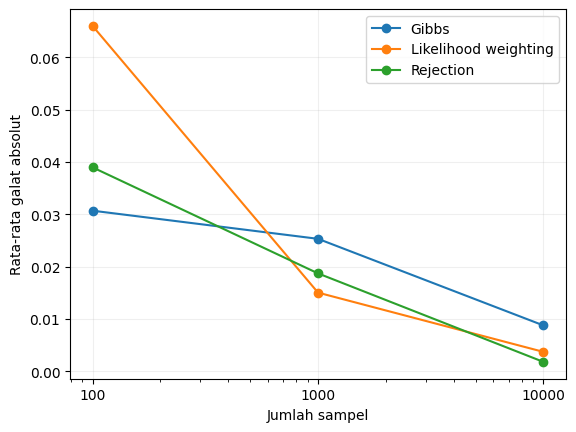

,Seed,Sampel diterima
0,7,1
1,21,2
2,42,1


P(J=True, M=True) = 0.0020841002
Perkiraan diterima dari 1000 sampel = 2.0841


In [17]:
exact5 = enumeration_ask("Rain", wet_evidence, sprinkler)[True]
sample_sizes = [100, 1_000, 10_000]
seeds = [7, 21, 42]
rows5 = []

for sample_count in sample_sizes:
    for seed in seeds:
        rejection, accepted = rejection_sampling(
            "Rain", wet_evidence, sprinkler, sample_count,
            np.random.default_rng(seed))
        weighted = likelihood_weighting(
            "Rain", wet_evidence, sprinkler, sample_count,
            np.random.default_rng(seed))
        gibbs = gibbs_ask(
            "Rain", wet_evidence, sprinkler, sample_count,
            np.random.default_rng(seed))
        methods = {
            "Rejection": rejection,
            "Likelihood weighting": weighted,
            "Gibbs": gibbs,
        }
        for method, result in methods.items():
            estimate = result[True] if result is not None else np.nan
            rows5.append({
                "Metode": method,
                "Seed": seed,
                "Jumlah sampel": sample_count,
                "Taksiran": estimate,
                "Galat absolut": (abs(estimate - exact5)
                                  if result is not None else np.nan),
                "Sampel diterima": (accepted
                                    if method == "Rejection" else np.nan),
            })

table5 = pd.DataFrame(rows5)
display(table5.round(6))

mean_error5 = (
    table5.groupby(["Metode", "Jumlah sampel"])["Galat absolut"]
    .mean()
    .reset_index()
)
display(mean_error5.pivot(index="Jumlah sampel", columns="Metode",
                          values="Galat absolut").round(6))

for method, group in mean_error5.groupby("Metode"):
    plt.plot(group["Jumlah sampel"], group["Galat absolut"],
             marker="o", label=method)
plt.xscale("log")
plt.xlabel("Jumlah sampel")
plt.ylabel("Rata-rata galat absolut")
plt.xticks(sample_sizes, [str(value) for value in sample_sizes])
plt.grid(alpha=0.2)
plt.legend()
plt.show()

alarm_evidence = {"JohnCalls": True, "MaryCalls": True}
p_jm = full_joint[
    full_joint["JohnCalls"] & full_joint["MaryCalls"]
]["probability"].sum()
expected_accepted = 1_000 * p_jm
accepted_rows = []
for seed in seeds:
    _, accepted = rejection_sampling(
        "Burglary", alarm_evidence, burglary, 1_000,
        np.random.default_rng(seed))
    accepted_rows.append({"Seed": seed, "Sampel diterima": accepted})
display(pd.DataFrame(accepted_rows))
print(f"P(J=True, M=True) = {p_jm:.10f}")
print(f"Perkiraan diterima dari 1000 sampel = {expected_accepted:.4f}")

<details>
<summary>Klik untuk melihat petunjuk</summary>

Gunakan generator acak baru untuk setiap kombinasi metode, seed, dan jumlah sampel agar percobaan dapat diulang. Hitung galat absolut sebagai selisih mutlak taksiran terhadap nilai exact. Kelompokkan tabel berdasarkan metode dan jumlah sampel untuk menghitung rata-rata antar-seed. Pada nomor 4, perkiraan jumlah sampel yang diterima adalah $N\times P(evidence)$; jumlah aktual dapat berbeda karena pengambilan sampel bersifat acak.

</details>